In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

## Задание 2.1

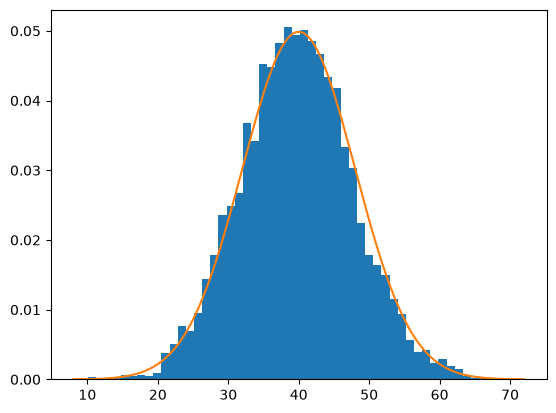

In [2]:
mu, sigma = 40, 8
sample = np.random.normal(mu, sigma, size=5000)
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 200)

plt.hist(sample, bins=50, density=True)
plt.plot(x, stats.norm.pdf(x, mu, sigma))
plt.show()

In [3]:
print(f"sample mean = {round(sample.mean(), 4)},\nsample std = {round(sample.std(), 4)}")

sample mean = 39.7161,
sample std = 7.9507


Среднее и ско по выборке очень близки к заданным.

## Задание 2.2

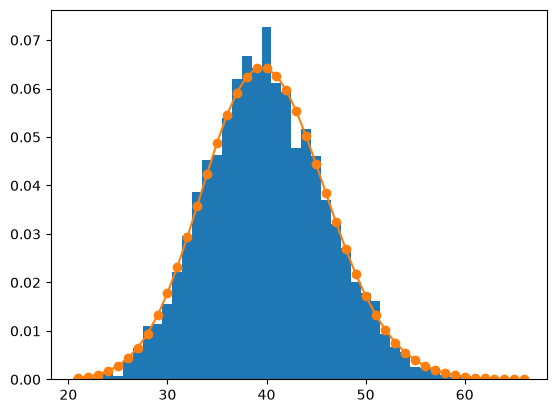

In [4]:
n, p = 1000, 0.04
sample = np.random.binomial(n, p, size=5000)
k = np.arange(sample.min(), sample.max() + 1)

plt.hist(sample, bins=k - 0.5, density=True)
plt.plot(k, stats.binom.pmf(k, n, p), 'o-')
plt.show()

In [5]:
print(f"real mean = {round(n * p, 4)},\nreal std = {round(np.sqrt((n * p * (1 - p))), 4)}")
print(f"sample mean = {round(sample.mean(), 4)},\nsample std = {round(sample.std(), 4)}")

real mean = 40.0,
real std = 6.1968
sample mean = 40.0058,
sample std = 6.041


Среднее и ско по выборке очень близки к заданным.

## Задание 2.3

In [6]:
sample = np.random.exponential(size=5000)
print(f"sample mean = {round(sample.mean(), 4)},\nsample std = {round(sample.std(), 4)}")

sample mean = 0.9867,
sample std = 0.983


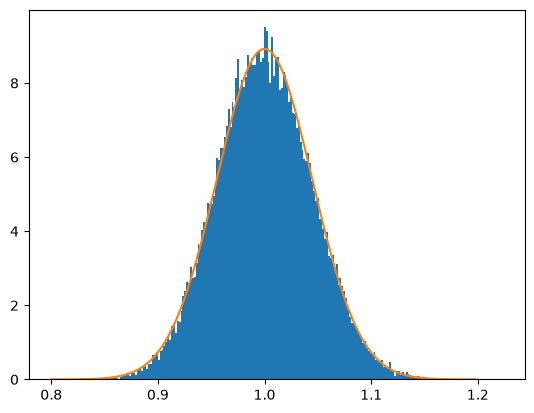

In [7]:
mu, sigma = 1, 1
samples_means = []

for _ in range(50000):
    sample = np.random.exponential(size=500)
    samples_means.append(sample.mean())

xs = np.linspace(0.8, 1.2, 200)

plt.hist(samples_means, bins=int(np.sqrt(len(samples_means))), density=True)
plt.plot(xs, stats.norm.pdf(xs, mu, sigma / np.sqrt(500)))
plt.show()

На гистограмме мы видим, что распределение средних множества независимых выборок стремится к нормальному распределению. Это происходит из-за центрально предельной теоремы, которая гласит: выборочное среднее распределено примерно нормально при достаточно большом количестве наблюдений и конечной дисперсии.

## Задание 3.1

In [8]:
old_cand, old_resp, old_conv = 5000, 155, 0.031
new_cand, new_resp, new_conv = 5000, 170, 0.034

old_se = np.sqrt(old_conv * (1 - old_conv) / old_cand)
new_se = np.sqrt(new_conv * (1 - new_conv) / new_cand)
se_diff = np.sqrt(old_se**2 + new_se**2)
obs_diff = new_conv - old_conv

print(f"{old_se=:.4f}, {new_se=:.4f}")
print(f"{se_diff=:.4f}, {obs_diff=:.4f}")

old_se=0.0025, new_se=0.0026
se_diff=0.0035, obs_diff=0.0030


Стандартная ошибка разницы больше, чем разница в конверсиях (0.0035 > 0.003), значит предварительный вывод: эффект не доказан, разницу нельзя отличить от случайного шума.

## Задание 3.2

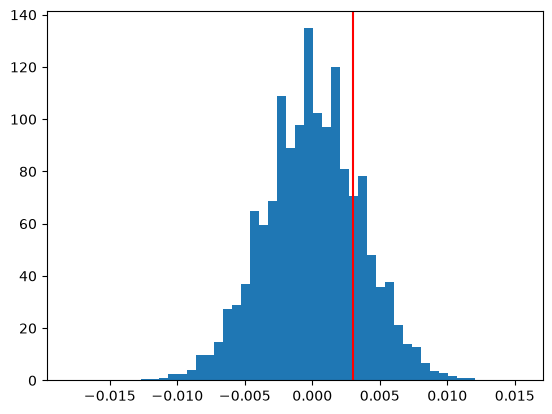

0.20702
0.41245


In [9]:
# общая вероятность
p = (old_conv + new_conv) / 2
sims = 100_000

old = np.random.binomial(n=5000, p=p, size=sims) / 5000
new = np.random.binomial(n=5000, p=p, size=sims) / 5000
diff = new - old

plt.hist(diff, bins=50, density=True)
plt.axvline(0.003, color='r')
plt.show()

print((diff >= 0.003 - 1e-9).mean())
print((np.abs(diff) >= 0.003 - 1e-9).mean())


Если кнопка ни на что не влияет, случайность даёт разницу не меньше 0,3 п.п. примерно в каждом пятом эксперименте (около 41%, если считать разницу любого знака). Значит, наблюдаемая разница вполне могла получиться случайно: данные не позволяют отличить эффект кнопки от шума. Чтобы это проверить, нужна выборка больше

## Задание 3.3

In [10]:
data = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])

mu = data.mean()
var = (data**2).mean() - mu**2
sigma = np.sqrt(var)

outliers_3sigm = [x for x  in data if not (mu - 3*sigma <= x <= mu + 3*sigma)]
perc_99 = np.percentile(data, 99)
outliers_perc99 = [x for x in data if x >= perc_99]

print(mu, var, sigma, mu + 3*sigma, perc_99)
print(outliers_3sigm)
print(outliers_perc99)

10.0 198.0 14.071247279470288 52.21374183841087 48.040000000000006
[]
[np.int64(52)]


Способ с перцентилями сработал лучше, так как порог в 3 сигмы немного превысил значение нашего явного выброса (52.2). Это происходит из-за того, что большой выброс сам раздувает наше среднее и ско. При этом способ с перцентилями имеет недостаток, который заключается в том, что он обязательно отсечет часть данных, даже если в них выбросо и нет. Способ нужно выбирать исходя из задачи.